# 03 - SVM, Random Forest & KNN (C)

# 1. Preparation

## 1.1 Imports

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PROCESSED_DIR, RESULTS, RANDOM_STATE, TEXT_COL
from src.evaluate import evaluate, save_results
from src.model import build_pipeline

from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score



## 1.2 Loading the data

In [2]:
# Load cleaned datasets
train = pd.read_csv(PROCESSED_DIR / "train.csv")
val = pd.read_csv(PROCESSED_DIR / "validation.csv")

# A cleaned tweet can be empty; it is read back as NaN, which would crash TF-IDF
train[TEXT_COL] = train[TEXT_COL].fillna("")
val[TEXT_COL] = val[TEXT_COL].fillna("")

# Separate features and labels
X_train, y_train = train[TEXT_COL], train["label"]
X_val, y_val = val[TEXT_COL], val["label"]

# Check dimensions
print("Training:", X_train.shape)
print("Validation:", X_val.shape)

# cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


Training: (2859,)
Validation: (955,)


# 2. SVM

## 2.1 Baseline: SVM with default settings

Before tuning anything, we train **one simple SVM with its default settings** through the shared pipeline (TF-IDF + model).

We only test the linear version: for sparse, high-dimensional text, a straight boundary is the standard choice, and it is much faster than a curved (rbf) kernel.

---SVM baseline---
              precision    recall  f1-score   support

   non_irony      0.637     0.627     0.632       499
       irony      0.599     0.610     0.604       456

    accuracy                          0.619       955
   macro avg      0.618     0.618     0.618       955
weighted avg      0.619     0.619     0.619       955



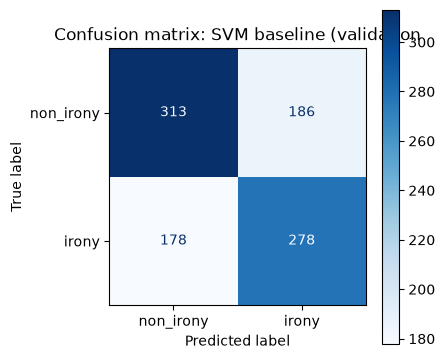

Number of TF-IDF features: 6976


{'model': 'SVM baseline',
 'split': 'validation',
 'accuracy': 0.618848167539267,
 'precision': 0.5991379310344828,
 'recall': 0.6096491228070176,
 'f1': 0.6043478260869565,
 'f1_macro': 0.6183355292050944}

In [3]:

# Shared pipeline = TF-IDF vectorizer + a default SVM
baseline = build_pipeline(LinearSVC(random_state=RANDOM_STATE))

# Learn on the training tweets only (the pipeline fits TF-IDF on train too, so no leakage)
baseline.fit(X_train, y_train)

# Predict the validation tweets and score them with the team's evaluate()
y_pred = baseline.predict(X_val)
metrics_base = evaluate("SVM baseline", y_val, y_pred, save_fig=False)

# How many numbers (features) describe each tweet after TF-IDF?
n_features = len(baseline.named_steps["tfidf"].get_feature_names_out())
print("Number of TF-IDF features:", n_features)
metrics_base

## 2.2 Tuning the SVM with GridSearchCV

The SVM has one important setting (a **hyperparameter**): `C`, which controls how strict the model is on the training tweets.
- **small C** → the model accepts some mistakes on train and keeps a smooth, simple boundary (less overfitting)
- **large C** → the model tries hard to classify every training tweet correctly (risk of overfitting)

We test 7 values of `C` with `GridSearchCV`: for each value, it trains and scores the pipeline with **5-fold cross-validation on the training set only**, using **macro-F1**.
The best `C` is then evaluated once on the validation split.



Best parameters: {'clf__C': 0.5}
Best CV macro-F1: 0.6175


,param_clf__C,mean_test_score,std_test_score,rank_test_score
0,0.01,0.5736,0.0116,7
1,0.10,0.6167,0.0225,2
2,0.50,0.6175,0.0177,1
3,1.00,0.6105,0.0197,3
4,5.00,0.5926,0.0173,4
5,10.00,0.5874,0.0184,5
6,100.00,0.5803,0.0164,6


---SVM tuned---
              precision    recall  f1-score   support

   non_irony      0.642     0.615     0.628       499
       irony      0.597     0.625     0.611       456

    accuracy                          0.620       955
   macro avg      0.620     0.620     0.620       955
weighted avg      0.621     0.620     0.620       955



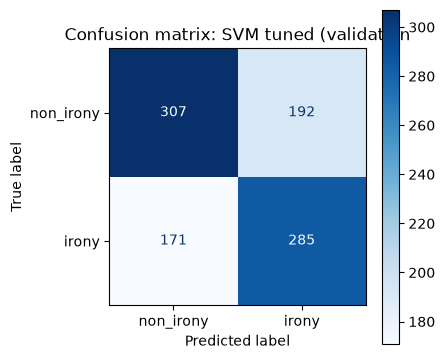

In [4]:

# Same shared pipeline; max_iter is raised so that large values of C can converge
pipe_svm = build_pipeline(LinearSVC(max_iter=10000, random_state=RANDOM_STATE))

# Values of C to try 
param_grid_svm = {"clf__C": [0.01, 0.1, 0.5, 1, 5, 10, 100]}

# 5-fold cross-validation on TRAIN, scored with macro-F1 
grid_svm = GridSearchCV(pipe_svm, param_grid_svm, cv=cv, scoring="f1_macro", n_jobs=-1)
grid_svm.fit(X_train, y_train)

print("Best parameters:", grid_svm.best_params_)
print("Best CV macro-F1:", round(grid_svm.best_score_, 4))

# Table of all the tested values
cv_svm = pd.DataFrame(grid_svm.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score", "rank_test_score"]]
display(cv_svm.round(4))

# Evaluate the best SVM on the validation split
y_pred_svm = grid_svm.predict(X_val)
metrics_svm = evaluate("SVM tuned", y_val, y_pred_svm)

## 2.3 Overfitting check


In [5]:

train_f1_svm = f1_score(y_train, grid_svm.predict(X_train), average="macro")
val_f1_svm = metrics_svm["f1_macro"]

print("Train macro-F1     :", round(train_f1_svm, 4))
print("Validation macro-F1:", round(val_f1_svm, 4))
print("Gap                :", round(train_f1_svm - val_f1_svm, 4))

Train macro-F1     : 0.9755
Validation macro-F1: 0.6197
Gap                : 0.3558


The SVM scores 0.976 on the training tweets but only 0.620 on validation (gap 0.356). We have 6,976 features for only 2,859 tweets, so a straight-line boundary can almost always separate the training tweets perfectly. The gap shows that the model memorizes the training data. It does not mean that C was badly chosen, since C was chosen by cross-validation.

# 3. Random Forest

A `Random Forest` is a group of many decision trees. Each tree asks a series of yes/no questions about the tweet (for example "does it contain the word *love*?") and votes ironic or not ironic. The forest takes the `majority vote`.
Each tree sees a random sample of the tweets and a random subset of the words at each split, so the trees make different mistakes and the vote is more reliable than a single tree.

## 3.1 Baseline with default settings

---RF baseline---
              precision    recall  f1-score   support

   non_irony      0.642     0.585     0.612       499
       irony      0.586     0.643     0.613       456

    accuracy                          0.613       955
   macro avg      0.614     0.614     0.613       955
weighted avg      0.615     0.613     0.613       955



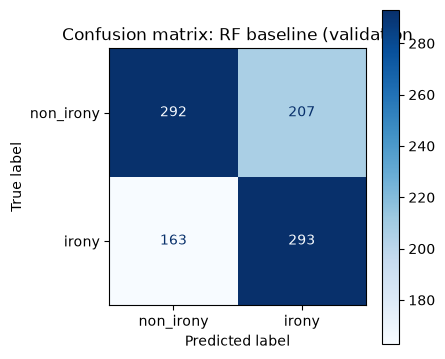

{'model': 'RF baseline',
 'split': 'validation',
 'accuracy': 0.612565445026178,
 'precision': 0.586,
 'recall': 0.6425438596491229,
 'f1': 0.6129707112970711,
 'f1_macro': 0.6125650202187662}

In [6]:

# Default Random Forest through the shared pipeline
rf_base = build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
rf_base.fit(X_train, y_train)

metrics_rf_base = evaluate("RF baseline", y_val, rf_base.predict(X_val), save_fig=False)
metrics_rf_base

## 3.2 Tuning with GridSearchCV

We tune three hyperparameters (5-fold CV on train, macro-F1):
- `n_estimators`: number of trees in the forest
- `max_depth`: maximum number of questions a tree can ask in a row (`None` = no limit)
- `min_samples_leaf`: minimum number of tweets in a final leaf (larger = simpler trees, less overfitting)


In [7]:
pipe_rf = build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE))

param_grid_rf = {
    "clf__n_estimators": [100, 300],
    "clf__max_depth": [None, 50],
    "clf__min_samples_leaf": [1, 3],
}

grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv, scoring="f1_macro", n_jobs=-1)
grid_rf.fit(X_train, y_train)

print("Best parameters:", grid_rf.best_params_)
print("Best CV macro-F1:", round(grid_rf.best_score_, 4))

Best parameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
Best CV macro-F1: 0.6302


## 3.3 All tested combinations

`mean_test_score` is the average macro-F1 over the 5 folds and `std_test_score` is how much the 5 scores vary.
A gap between two rows that is smaller than the std is probably just luck.

In [8]:
cv_rf = pd.DataFrame(grid_rf.cv_results_)[[
    "param_clf__n_estimators", "param_clf__max_depth", "param_clf__min_samples_leaf",
    "mean_test_score", "std_test_score", "rank_test_score"]]

display(cv_rf.sort_values("rank_test_score").round(4))

,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
0,100,None,1,0.6302,0.0154,1
2,100,None,3,0.6232,0.0232,2
6,100,50,3,0.6221,0.0222,3
5,300,50,1,0.6208,0.0143,4
7,300,50,3,0.6202,0.0227,5
4,100,50,1,0.6198,0.0054,6
1,300,None,1,0.6192,0.0150,7
3,300,None,3,0.6190,0.0163,8


## 3.4 Evaluation of the best forest on validation

---Random Forest tuned---
              precision    recall  f1-score   support

   non_irony      0.642     0.585     0.612       499
       irony      0.586     0.643     0.613       456

    accuracy                          0.613       955
   macro avg      0.614     0.614     0.613       955
weighted avg      0.615     0.613     0.613       955



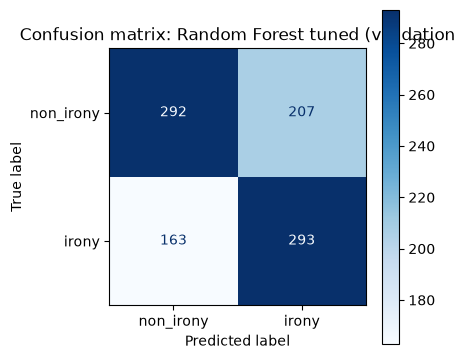

In [9]:
y_pred_rf = grid_rf.predict(X_val)
metrics_rf = evaluate("Random Forest tuned", y_val, y_pred_rf)

## 3.5 Overfitting check


In [10]:
train_f1 = f1_score(y_train, grid_rf.predict(X_train), average="macro")
val_f1 = metrics_rf["f1_macro"]

print("Train macro-F1     :", round(train_f1, 4))
print("Validation macro-F1:", round(val_f1, 4))
print("Gap                :", round(train_f1 - val_f1, 4))

Train macro-F1     : 0.9997
Validation macro-F1: 0.6126
Gap                : 0.3871


The forest scores 0.9997 on the training tweets and 0.613 on validation (gap 0.387). With no depth limit and leaves of one tweet, every tree grows until it fits its training sample almost perfectly, and a Random Forest always scores close to perfect on data it has already seen, so the validation score is the one to trust. The best settings are also scikit-learn's defaults, so tuning did not change the model.

# 4. KNN (K-Nearest Neighbors)

KNN does not really "learn" anything. It **stores all the training tweets**, and to classify a new tweet it finds the `k` most similar training tweets (its *neighbors*) and takes the **majority vote** of their labels.
"Similar" means close in the TF-IDF space: two tweets that share many of the same (weighted) words are close.

## 4.1 Baseline with default settings

---KNN baseline---
              precision    recall  f1-score   support

   non_irony      0.703     0.194     0.305       499
       irony      0.508     0.910     0.652       456

    accuracy                          0.536       955
   macro avg      0.605     0.552     0.478       955
weighted avg      0.610     0.536     0.470       955



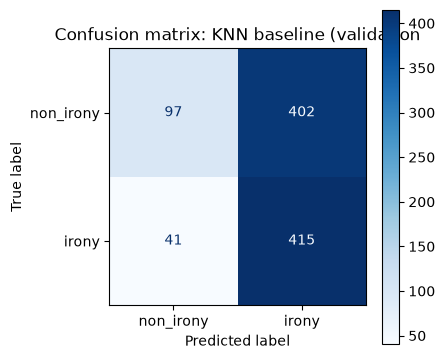

{'model': 'KNN baseline',
 'split': 'validation',
 'accuracy': 0.5361256544502618,
 'precision': 0.5079559363525091,
 'recall': 0.9100877192982456,
 'f1': 0.6520031421838177,
 'f1_macro': 0.47827786622534685}

In [11]:

# Default KNN (k = 5) through the shared pipeline
knn_base = build_pipeline(KNeighborsClassifier())
knn_base.fit(X_train, y_train)

metrics_knn_base = evaluate("KNN baseline", y_val, knn_base.predict(X_val), save_fig=False)
metrics_knn_base

## 4.2 Tuning with GridSearchCV

We tune three hyperparameters (stratified 5-fold CV on train, macro-F1):
- `n_neighbors` (k): how many neighbors vote. Small k = very sensitive to single tweets, large k = smoother but less precise.
- `weights`: `uniform` = every neighbor counts the same, `distance` = closer neighbors count more.
- `metric`: how "close" is measured. `euclidean` = straight-line distance, `cosine` = the angle between two tweets, which ignores their length. Cosine is the usual choice for text.

In [12]:
pipe_knn = build_pipeline(KNeighborsClassifier())

param_grid_knn = {
    "clf__n_neighbors": [3, 5, 11, 21, 41, 81, 91, 101],
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["euclidean", "cosine"],
}

grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=cv, scoring="f1_macro", n_jobs=-1)
grid_knn.fit(X_train, y_train)

print("Best parameters:", grid_knn.best_params_)
print("Best CV macro-F1:", round(grid_knn.best_score_, 4))

Best parameters: {'clf__metric': 'cosine', 'clf__n_neighbors': 21, 'clf__weights': 'distance'}
Best CV macro-F1: 0.6025


## 4.3 All tested combinations

In [13]:
cv_knn = pd.DataFrame(grid_knn.cv_results_)[[
    "param_clf__n_neighbors", "param_clf__weights", "param_clf__metric",
    "mean_test_score", "std_test_score", "rank_test_score"]]

display(cv_knn.sort_values("rank_test_score").head(10).round(4))

,param_clf__n_neighbors,param_clf__weights,param_clf__metric,mean_test_score,std_test_score,rank_test_score
23,21,distance,cosine,0.6025,0.0007,1
22,21,uniform,cosine,0.6018,0.0044,2
24,41,uniform,cosine,0.6014,0.0109,3
25,41,distance,cosine,0.6013,0.0098,4
8,41,uniform,euclidean,0.6000,0.0110,5
9,41,distance,euclidean,0.5996,0.0107,6
15,101,distance,euclidean,0.5980,0.0207,7
31,101,distance,cosine,0.5967,0.0229,8
29,91,distance,cosine,0.5965,0.0177,9
14,101,uniform,euclidean,0.5954,0.0237,10


## 4.4 Evaluation of the best KNN on validation

---KNN tuned---
              precision    recall  f1-score   support

   non_irony      0.653     0.677     0.665       499
       irony      0.632     0.605     0.618       456

    accuracy                          0.643       955
   macro avg      0.642     0.641     0.641       955
weighted avg      0.643     0.643     0.642       955



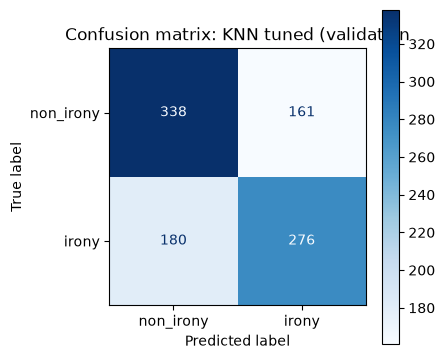

In [14]:
y_pred_knn = grid_knn.predict(X_val)
metrics_knn = evaluate("KNN tuned", y_val, y_pred_knn)

## 4.5 Overfitting check


In [15]:
train_f1_knn = f1_score(y_train, grid_knn.predict(X_train), average="macro")
val_f1_knn = metrics_knn["f1_macro"]

print("Train macro-F1     :", round(train_f1_knn, 4))
print("Validation macro-F1:", round(val_f1_knn, 4))
print("Gap                :", round(train_f1_knn - val_f1_knn, 4))

Train macro-F1     : 0.999
Validation macro-F1: 0.6414
Gap                : 0.3575


KNN scores 0.640 on the training tweets and 0.611 on validation (gap 0.028). The gap is small because the best model uses k = 41 with uniform weights: each prediction is a vote of 41 neighbors, so the model cannot memorize single tweets. A small gap here does not mean the model is good, because both scores are low. (With `weights="distance"` the train score would be about 1.0 by construction, since a training tweet is its own nearest neighbor at distance 0.)

# 5. Why do these models struggle with text and irony?

## 5.1 Summary of the three models

We put the results of sections 2, 3 and 4 side by side: score before tuning, best cross-validation score, score after tuning on validation, and score on the training tweets.

In [16]:
summary = pd.DataFrame({
    "Baseline macro-F1": [metrics_base["f1_macro"], metrics_rf_base["f1_macro"], metrics_knn_base["f1_macro"]],
    "Best CV macro-F1":  [grid_svm.best_score_,     grid_rf.best_score_,         grid_knn.best_score_],
    "Tuned macro-F1":    [metrics_svm["f1_macro"],  metrics_rf["f1_macro"],      metrics_knn["f1_macro"]],
    "Train macro-F1":    [train_f1_svm,             train_f1,                    train_f1_knn],
}, index=["SVM", "Random Forest", "KNN"])

summary["Gain from tuning"] = summary["Tuned macro-F1"] - summary["Baseline macro-F1"]
summary["Train-validation gap"] = summary["Train macro-F1"] - summary["Tuned macro-F1"]

summary.round(3)

,Baseline macro-F1,Best CV macro-F1,Tuned macro-F1,Train macro-F1,Gain from tuning,Train-validation gap
SVM,0.618,0.617,0.620,0.976,0.001,0.356
Random Forest,0.613,0.630,0.613,1.000,0.000,0.387
KNN,0.478,0.602,0.641,0.999,0.163,0.358
